<a href="https://colab.research.google.com/github/juleuzun/Python_DataScience_Bootcamp/blob/main/Assignments/Assignment_9_Image_Classification_using_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Image Classification using CNN (Convolutional Neural Network)**

# Libraries

In [ ]:
# Fashion_MNIST dataset
from tensorflow.keras.datasets import fashion_mnist

# CNN model
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, ReLU

# Visualization
import matplotlib.pyplot as plt

# Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Fashion-MNIST dataset loading

In [ ]:
(X_train, y_train), (X_test,y_test) = fashion_mnist.load_data()

print("Training data:", X_train.shape)
print("Training labels:",y_train.shape)
print("Test data:", X_test.shape)
print("Test labels:",y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data: (60000, 28, 28)
Training labels: (60000,)
Test data: (10000, 28, 28)
Test labels: (10000,)


# Defining class names

In [ ]:
# Class names in the Fashion-MNIST dataset
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

# Class numbers and names
for i, class_name in enumerate(class_names):
    print(i, "-", class_name)


0 - T-shirt/top
1 - Trouser
2 - Pullover
3 - Dress
4 - Coat
5 - Sandal
6 - Shirt
7 - Sneaker
8 - Bag
9 - Ankle boot


# Inspecting Example Images

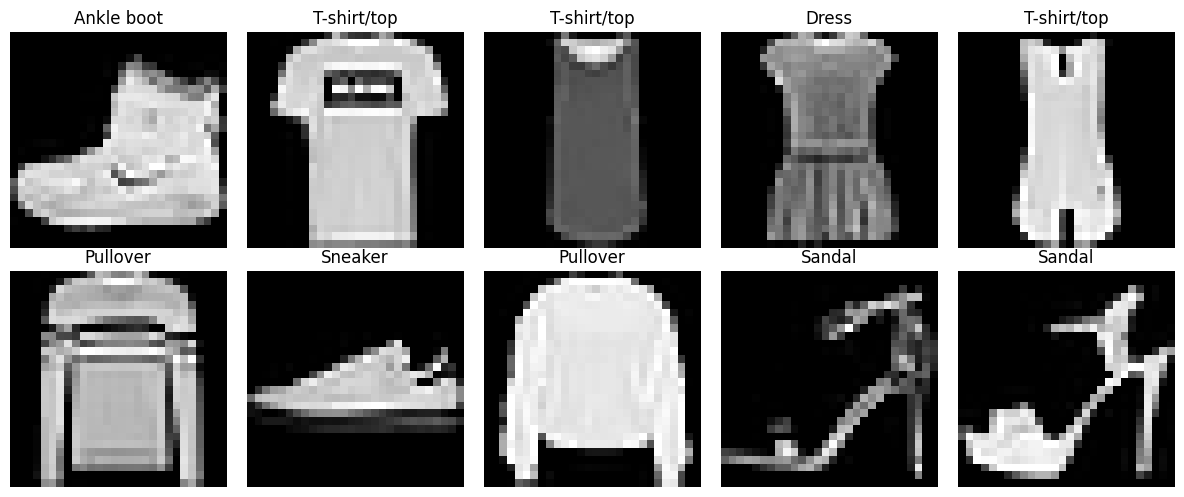

In [ ]:
 # First 10 images from the training dataset

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    # Display the image in grayscale
    plt.imshow(X_train[i], cmap='gray')

    # Display the true class of the image as the title
    plt.title(class_names[y_train[i]])

    # Turn off axes
    plt.axis("off")

plt.tight_layout()
plt.show()

# Reshaping and Normalizing Images

In [ ]:
# To reshape the images to the format expected by the CNN
# Previous shape: (28, 28)
# New shape: (28, 28, 1)
#
# The 1 here indicates that the image is single-channel, meaning grayscale.

X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Pixel values are between 0 and 255
# By dividing by 255.0, we scale the values to a 0 - 1 range.

X_train = X_train / 255.0
X_test = X_test / 255.0

print("New shape of X_train:", X_train.shape)
print("New shape of X_test:", X_test.shape)

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())


New shape of X_train: (60000, 28, 28, 1)
New shape of X_test: (10000, 28, 28, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


#CNN (Convolutional Neural Network) model building

In [ ]:
# Create the CNN model using the Sequential structure

cnn_model = Sequential([

  # 1st Convolutional layer
  # Use 32 filters
  Conv2D(
      32,
      (3,3),
      activation="relu",
      input_shape=(28, 28, 1)
  ),

  # Reduce the spatial dimensions of the image
  MaxPooling2D((2, 2)),

  # 2nd Convolutional Layer
  # Use 64 filters in this layer
  Conv2D(64, (3, 3)),

  # ReLU activation
  ReLU(),

  # Dimensionality reduction
  MaxPooling2D((2, 2)),

  # Flatten the feature maps from convolutional layers into a 1D vector
  Flatten(),

  # Fully connected layers (Dense layers)
  Dense(128, activation="relu"),
  Dense(64, activation="relu"),
  Dense(32, activation="relu"),

  # Output layer
  # Since there are 10 classes, we use 10 neurons.
  # Softmax produces a probability distribution over the classes.
  Dense(10, activation="softmax")

])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


# Displaying the Model Summary

In [ ]:
# Display the layers and the number of parameters in the model
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 234,410 (915.66 KB)

 Trainable params: 234,410 (915.66 KB)

 Non-trainable params: 0 (0.00 B)

# Compiling the Model

In [ ]:
 # Compile the CNN model
 cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Training CNN Model

In [ ]:
# Training the CNN Model
history = cnn_model.fit(
    X_train,
    y_train,
    epochs=10,  # The model will see the entire training dataset 10 times.
    batch_size=64,  # The model will update its weights in batches of 64 images.
    validation_data=(X_test, y_test)  # To monitor the test data accuracy during training
)


Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 50s 51ms/step - accuracy: 0.7951 - loss: 0.5565 - val_accuracy: 0.8447 - val_loss: 0.4303
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 82s 52ms/step - accuracy: 0.8715 - loss: 0.3526 - val_accuracy: 0.8729 - val_loss: 0.3498
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 48s 52ms/step - accuracy: 0.8894 - loss: 0.3007 - val_accuracy: 0.8901 - val_loss: 0.3113
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 81s 51ms/step - accuracy: 0.9018 - loss: 0.2675 - val_accuracy: 0.8928 - val_loss: 0.2968
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 84s 53ms/step - accuracy: 0.9112 - loss: 0.2416 - val_accuracy: 0.9036 - val_loss: 0.2695
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 87s 58ms/step - accuracy: 0.9178 - loss: 0.2193 - val_accuracy: 0.9065 - val_loss: 0.2660
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 84s 61ms/step - accuracy: 0.9253 - loss: 0.1998 - val_accuracy: 0.9060 - val_loss: 0.2627
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 78s 57ms/step - accuracy: 0.9326 - loss: 0.1817 - 

# Visualizing Training Results

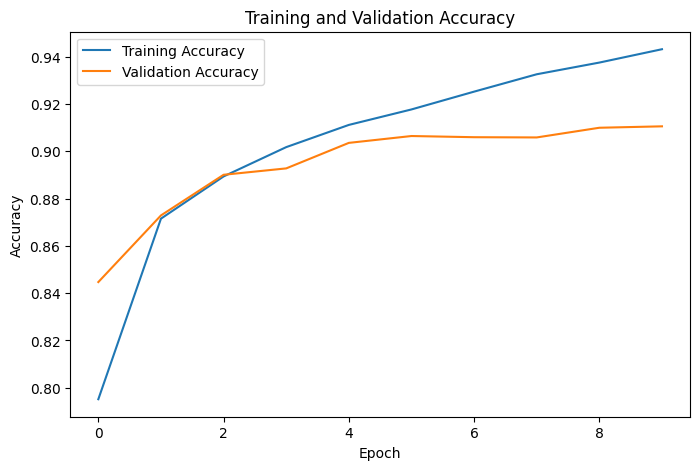

In [ ]:
  # Checking accuracy values during training

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()


# Measuring Accuracy on the Test Set

In [ ]:
# Evaluates the model's performance on unseen test data

test_loss, test_accuracy = cnn_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)
print("Test accuracy (%):", test_accuracy * 100)


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9106 - loss: 0.2579
Test loss: 0.2578652799129486
Test accuracy: 0.9106000065803528
Test accuracy (%): 91.06000065803528


# Predicting Test Images

In [ ]:
# Prediction probabilities for test images
prediction_probabilities = cnn_model.predict(X_test)

# Select the class with the highest probability for each image
y_pred = prediction_probabilities.argmax(axis=1)

print("First 20 true classes:")
print(y_test[:20])  # y_test shows the actual classes.

print("\nFirst 20 predictions:")
print(y_pred[:20])  # y_pred shows the classes predicted by the CNN.


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
First 20 true classes:
[9 2 1 1 6 1 4 6 5 7 4 5 7 3 4 1 2 4 8 0]

First 20 predictions:
[9 2 1 1 6 1 4 6 5 7 4 5 7 3 4 1 2 4 8 0]


# Displaying predictions with class names   

In [ ]:
# Shows the true and predicted classes of the first 20 images with their actual names

for i in range(20):
    print(
        f"Image {i + 1} | "
        f"True: {class_names[y_test[i]]} | "
        f"Predicted: {class_names[y_pred[i]]}"
    )


Image 1 | True: Ankle boot | Predicted: Ankle boot
Image 2 | True: Pullover | Predicted: Pullover
Image 3 | True: Trouser | Predicted: Trouser
Image 4 | True: Trouser | Predicted: Trouser
Image 5 | True: Shirt | Predicted: Shirt
Image 6 | True: Trouser | Predicted: Trouser
Image 7 | True: Coat | Predicted: Coat
Image 8 | True: Shirt | Predicted: Shirt
Image 9 | True: Sandal | Predicted: Sandal
Image 10 | True: Sneaker | Predicted: Sneaker
Image 11 | True: Coat | Predicted: Coat
Image 12 | True: Sandal | Predicted: Sandal
Image 13 | True: Sneaker | Predicted: Sneaker
Image 14 | True: Dress | Predicted: Dress
Image 15 | True: Coat | Predicted: Coat
Image 16 | True: Trouser | Predicted: Trouser
Image 17 | True: Pullover | Predicted: Pullover
Image 18 | True: Coat | Predicted: Coat
Image 19 | True: Bag | Predicted: Bag
Image 20 | True: T-shirt/top | Predicted: T-shirt/top


# Creating the Confusion Matrix  

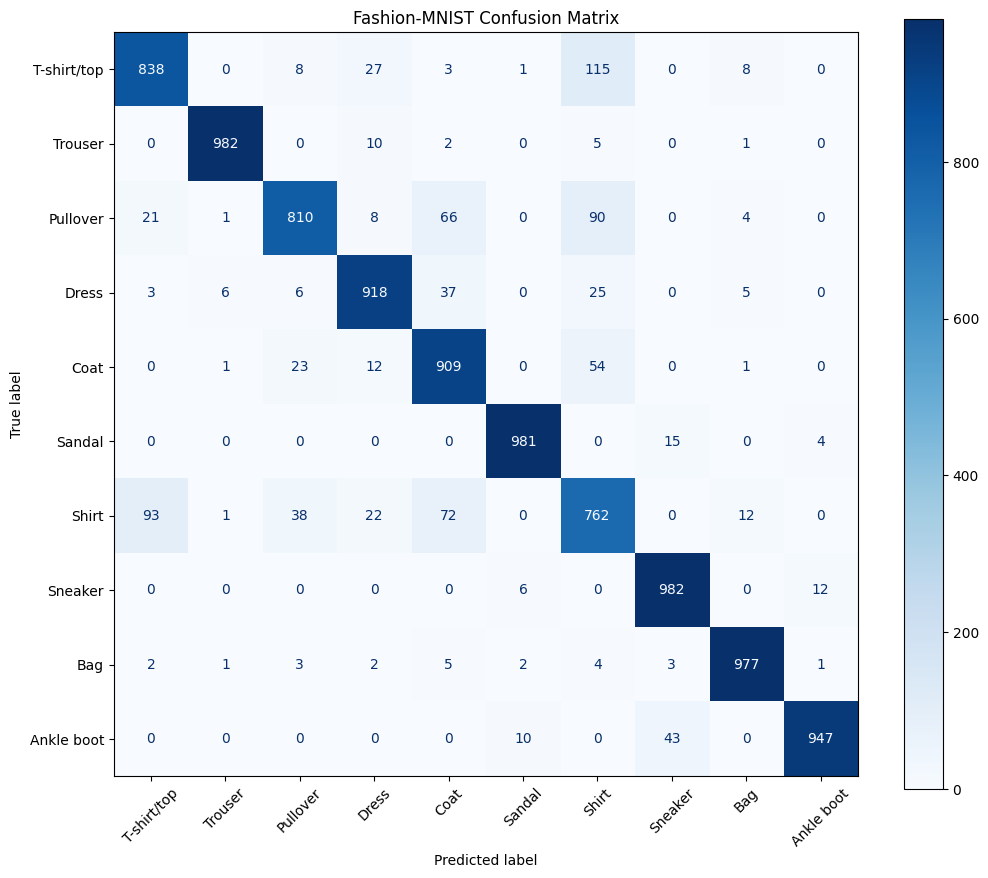

In [ ]:
 # Examines which classes the model confuses with one another
# Compare the true classes with the model's predictions

cm = confusion_matrix(y_test, y_pred)

# Visualizing the Confusion Matrix

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(12, 10))

disp.plot(
    ax=ax,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("Fashion-MNIST Confusion Matrix")
plt.show()


# Finding the most confused classes

In [ ]:
 # Since the values on the diagonal of the Confusion Matrix are correct predictions, the diagonal is zeroed out

cm_errors = cm.copy()

for i in range(len(cm_errors)):
    cm_errors[i, i] = 0

# Finding the most confused classes

print("Most confused classes:\n")

for _ in range(10):
    # Find the highest error
    index = cm_errors.argmax()

    true_class, pred_class = divmod(index, len(class_names))

    error_count = cm_errors[true_class, pred_class]

    if error_count == 0:
        break

    print(
        f"True: {class_names[true_class]} "
        f"-> Predicted: {class_names[pred_class]} "
        f"({error_count} times)"
    )

    # Zero out to find the next highest error in the next iteration
    cm_errors[true_class, pred_class] = 0


Most confused classes:

True: T-shirt/top -> Predicted: Shirt (115 times)
True: Shirt -> Predicted: T-shirt/top (93 times)
True: Pullover -> Predicted: Shirt (90 times)
True: Shirt -> Predicted: Coat (72 times)
True: Pullover -> Predicted: Coat (66 times)
True: Coat -> Predicted: Shirt (54 times)
True: Ankle boot -> Predicted: Sneaker (43 times)
True: Shirt -> Predicted: Pullover (38 times)
True: Dress -> Predicted: Coat (37 times)
True: T-shirt/top -> Predicted: Dress (27 times)


# Viewing Misclassified Examples  

In [ ]:
 # Indices of misclassified images

misclassified_indices = []

for i in range(len(y_test)):
    if y_test[i] != y_pred[i]:
        misclassified_indices.append(i)

print("Total number of misclassifications:", len(misclassified_indices))


Total number of misclassifications: 894


# Displaying Misclassified Images

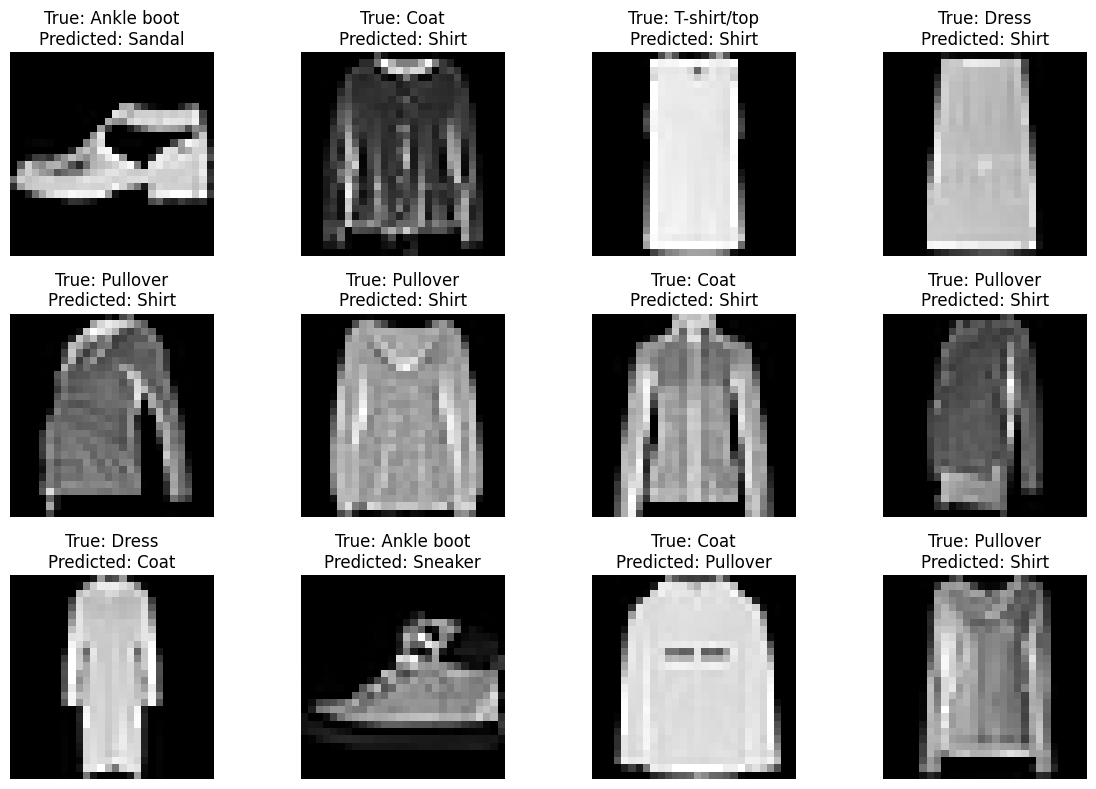

In [ ]:
 # First 12 misclassifications

plt.figure(figsize=(12, 8))

for i, index in enumerate(misclassified_indices[:12]):

    plt.subplot(3, 4, i + 1)

    # Display the image
    plt.imshow(X_test[index].reshape(28, 28), cmap="gray")

    # Display the true and predicted classes
    plt.title(
        f"True: {class_names[y_test[index]]}\n"
        f"Predicted: {class_names[y_pred[index]]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


# Conclusion

In this study, a Convolutional Neural Network (CNN) image classification model was developed using the Fashion-MNIST dataset.
The images were reshaped to dimensions of 28x28x1, and their pixel values were scaled to the 0-1 range. The model was constructed using the CNN architecture specified in the course notes and trained using the Adam optimization algorithm along with the sparse categorical crossentropy loss function.
The model was trained for 10 epochs, and its accuracy on the test dataset was measured.
The test accuracy is expected to be achieved at around the 90-92% level. The actual result obtained may vary due to the randomness inherent in the model's training process.
When the Confusion Matrix is examined, it can be observed that especially the visually similar classes—such as T-shirt/top, Pullover, Coat, and Shirt—tend to be confused with each other more frequently.
As a result, the CNN model successfully classified the clothing images in the Fashion-MNIST dataset.